# Predictive Modeling: Term Deposit Subscription

## Objective

Develop and evaluate classification models to predict whether
a bank customer will subscribe to a term deposit.

The models will use customer and campaign information available
before marketing contact, with attention to data leakage,
class imbalance, and evaluation on unseen data.


In [1]:
#Import libraries for data analysis and machine learning

import pandas as pd
import numpy as np

In [2]:
# Load the Bank Marketing dataset

df = pd.read_csv("../data/raw/bank-full.csv", sep = ";")

#Verify dataset dimensions
print("Dataset shape:", df.shape)

#Preview the first five records
df.head()

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
#Select customer features available before marketing contact

feature_columns = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "balance",
    "housing",
    "loan"
]
#Create feature matrix
X = df[feature_columns]

#Convert subscriptions outcome into binary values
y = df["y"].map({"no": 0, "yes": 1})

# Verify dimensions
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

#Preview selected features
X.head()

Feature matrix shape: (45211, 8)
Target shape: (45211,)


,age,job,marital,education,default,balance,housing,loan
0,58,management,married,tertiary,no,2143,yes,no
1,44,technician,single,secondary,no,29,yes,no
2,33,entrepreneur,married,secondary,no,2,yes,yes
3,47,blue-collar,married,unknown,no,1506,yes,no
4,33,unknown,single,unknown,no,1,no,no


In [4]:
# Import the function for splitting data

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

# Verify the dimensions of each dataset

print("Training features:", X_train.shape)
print("Testing features:", X_train.shape)

print("Training target:", y_train.shape)
print("Testing target", y_test.shape)

#Compare subscription rates between groups

print("Training subscription rate:", round(y_train.mean() * 100, 2), "%")
print("Testing subscription rate:", round(y_test.mean()* 100,2), "%")

Training features: (36168, 8)
Testing features: (36168, 8)
Training target: (36168,)
Testing target (9043,)
Training subscription rate: 11.7 %
Testing subscription rate: 11.7 %


In [5]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Define numerical and categorical features

numerical_features = ["age", "balance"]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

#Create preprocessing transformation

preprocessor = ColumnTransformer(
    transformers =[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
    ]
)
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [6]:
# Import tools for building a machine learning pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

#Create the logistic regression pipeline
logistic_model = Pipeline(
    steps = [
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter = 1000))
    ]
)

#Train the model using the training data
logistic_model.fit(X_train, y_train)

#Confirm successful training
print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


In [7]:
#Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#Generatee predictions using the testing data
logistic_predictions = logistic_model.predict(X_test)

#Calculate evaluation metrics
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions, zero_division = 0)
logistic_recall = recall_score(y_test, logistic_predictions, zero_division = 0)
logistic_f1 = f1_score(y_test, logistic_predictions, zero_division = 0)

#Display model performance
print(f"Logistic regression accuracy: {logistic_accuracy:.2%}")
print(f"Logistic regression precision: {logistic_precision:.2%}")
print(f"Logistic regression recall: {logistic_recall:.2%}")
print(f"Logistic regression F1 score: {logistic_f1:.2%}")


Logistic regression accuracy: 88.29%
Logistic regression precision: 0.00%
Logistic regression recall: 0.00%
Logistic regression F1 score: 0.00%


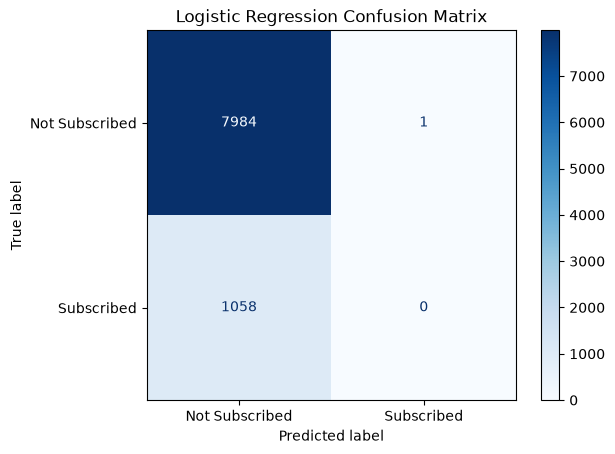

In [8]:

#Import visualization library
import matplotlib.pyplot as plt
#Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Calculate the confusion matrix
logistic_cm = confusion_matrix(y_test, logistic_predictions)

#Create the confusion matrix display
cm_display = ConfusionMatrixDisplay(
    confusion_matrix = logistic_cm,
    display_labels = ["Not Subscribed", "Subscribed"]
)

#Visualize the conufsion matrix
cm_display.plot(cmap = "Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [9]:
#Create a logistic regression model that accounts for class imbalance
balanced_logistic_model = Pipeline(
    steps = [
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            class_weight = "balanced",
            max_iter = 1000
        ))
    ]
)
# Train the balanced logistic regression model
balanced_logistic_model.fit(X_train, y_train)

#Generate predictions using the test data
balanced_predictions = balanced_logistic_model.predict(X_test)

print("Balanced logistic regression model trained successfully.")

Balanced logistic regression model trained successfully.


In [10]:
# Evaluate the balanced logistic regression model
balanced_accuracy = accuracy_score(y_test, balanced_predictions)
balanced_precision = precision_score(y_test, balanced_predictions, zero_division = 0)
balanced_recall = recall_score(y_test, balanced_predictions, zero_division = 0)
balanced_f1 = f1_score(y_test, balanced_predictions, zero_division = 0)

#Display model performance
print(f"Balanced logistic regression accuracy: {balanced_accuracy:.2%}")
print(f"Balanced logistic regression precision: {balanced_precision:.2%}")
print(f"Balanced logistic regression recall: {balanced_recall:.2%}")
print(f"Balanced logistic regression F1 score: {balanced_f1:.2%}")

Balanced logistic regression accuracy: 62.24%
Balanced logistic regression precision: 18.00%
Balanced logistic regression recall: 62.67%
Balanced logistic regression F1 score: 27.97%


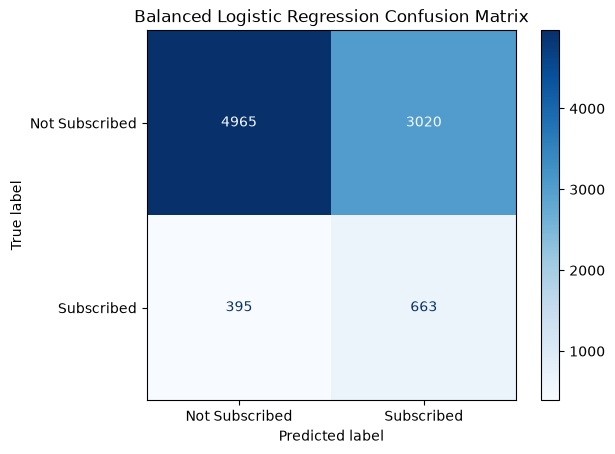

In [11]:
# Calculate the balanced model confusion matrix
balanced_cm = confusion_matrix(y_test, balanced_predictions)

#Create the confusion matrix display
balanced_display = ConfusionMatrixDisplay(
    confusion_matrix = balanced_cm,
    display_labels = ["Not Subscribed", "Subscribed"]
)

#Visualize the confusion matrix
balanced_display.plot(cmap = "Blues")
plt.title("Balanced Logistic Regression Confusion Matrix")
plt.show()

In [12]:
#Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

#Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators = 100,
            class_weight = "balanced",
            random_state = 42,
            n_jobs =-1
        ))
    ]
)

#Train the Random Forest model
random_forest_model.fit(X_train, y_train)

#Generate predictions using the test data
forest_predictions = random_forest_model.predict(X_test)

#Confirm successful training
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [13]:
#Evaluate the Random Forest model
forest_accuracy = accuracy_score(y_test, forest_predictions)
forest_precision = precision_score(y_test, forest_predictions, zero_division = 0)
forest_recall = recall_score(y_test, forest_predictions, zero_division = 0)
forest_f1 = f1_score(y_test, forest_predictions, zero_division = 0)

#Display Random Forest perfomance
print(f"Random Forest accuracy:{forest_accuracy:.2%}")
print(f"Random Forest precision: {forest_precision:.2%}")
print(f"Random Forest recall: {forest_recall:.2%}")
print(f"Random Forest F1 score: {forest_f1:.2%}")

Random Forest accuracy:82.47%
Random Forest precision: 29.87%
Random Forest recall: 36.96%
Random Forest F1 score: 33.04%


In [14]:
#Import ROC AUC evaluation metric
from sklearn.metrics import roc_auc_score

# Generate predicted subscription probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]
balanced_probabilities = balanced_logistic_model.predict_proba(X_test)[:, 1]
forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC AUC scores
logistic_auc = roc_auc_score(y_test, logistic_probabilities)
balanced_auc = roc_auc_score(y_test, balanced_probabilities)
forest_auc = roc_auc_score(y_test,forest_probabilities)

# Display ROC AUC scores
print(f"Original Logistic Regression ROC AUC: {logistic_auc:.3f}")
print(f"Balanced Logistic Regression ROC AUC: {balanced_auc:.3f}")
print(f"Random Forest ROC AUC: {forest_auc:.3f}")

Original Logistic Regression ROC AUC: 0.666
Balanced Logistic Regression ROC AUC: 0.666
Random Forest ROC AUC: 0.688


In [15]:
# Import Average Precision evaluation metric
from sklearn.metrics import average_precision_score

#Calculate Average Precision scores
logistic_ap = average_precision_score(y_test, logistic_probabilities)
balanced_ap = average_precision_score(y_test, balanced_probabilities)
forest_ap = average_precision_score(y_test, forest_probabilities)

#Display Average Precision scores
print(f"Original Logistic Regression AP: {logistic_ap:.3f}")
print(f"Balanced Logistic Regression AP: {balanced_ap:.3f}")
print(f"Random Forest AP: {forest_ap:.3f}")

Original Logistic Regression AP: 0.213
Balanced Logistic Regression AP: 0.211
Random Forest AP: 0.316


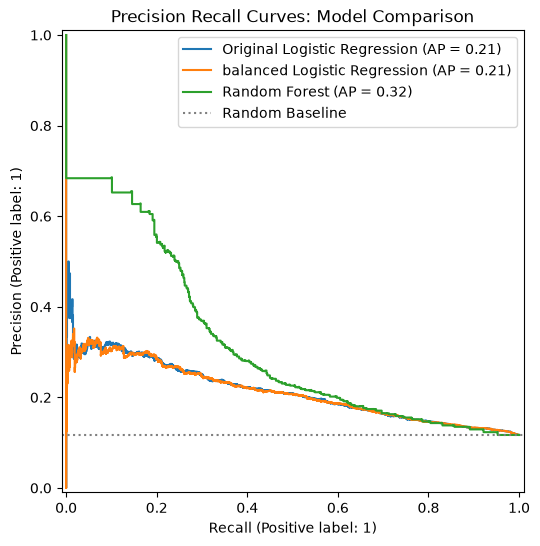

In [16]:
# Import precision recall visualization tool
from sklearn.metrics import PrecisionRecallDisplay

#Create figure
fig, ax = plt.subplots(figsize = (9,6))

# Plot original logistic regression
PrecisionRecallDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name = "Original Logistic Regression",
    ax = ax
)

# Plot balanced logistic regression
PrecisionRecallDisplay.from_predictions(
    y_test,
    balanced_probabilities,
    name = "balanced Logistic Regression",
    ax = ax
)
#Plot Random Forest
PrecisionRecallDisplay.from_predictions(
    y_test,
    forest_probabilities,
    name = "Random Forest",
    ax = ax
)

# Add random ranking baseline
ax.axhline(
    y = y_test.mean(),
    color = "gray",
    linestyle = ":",
    label = "Random Baseline"
)

# Format visulization
plt.title("Precision Recall Curves: Model Comparison")
plt.legend()
plt.show()

In [17]:
# Import permutation importance function
from sklearn.inspection import permutation_importance

# Calculate Random Forest feature importance
importance_results = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring = "average_precision",
    n_repeats = 5,
    random_state = 42,
    n_jobs = -1
)
#Create features by importance
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_results.importances_mean
})
#Sort features by importance
importance_df = importance_df.sort_values(
    by = "Importance",
    ascending = False
)
#Display results
print(importance_df.to_string(index= False))

  Feature  Importance
  balance    0.151119
      age    0.147307
      job    0.124608
  housing    0.099802
education    0.090727
  marital    0.084408
     loan    0.032066
  default    0.001510


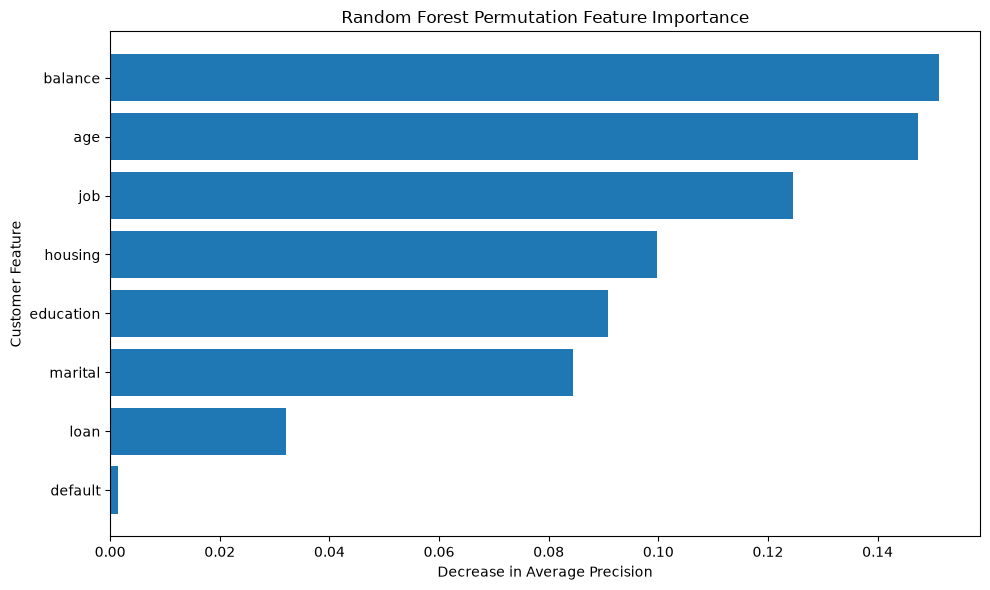

In [18]:
# Import visualization library
import matplotlib.pyplot as plt

#Create feature importance chart
plt.figure(figsize = (10,6))

plt.barh(
    importance_df["Feature"].iloc[::-1],
    importance_df["Importance"].iloc[::-1]
)
#Add chart labels
plt.xlabel("Decrease in Average Precision")
plt.ylabel("Customer Feature")
plt.title("Random Forest Permutation Feature Importance")

#Display chart
plt.tight_layout()

# Save visualization for the project README
plt.savefig("../plots/random_forest_feature_importance.png", dpi=300, bbox_inches="tight")

plt.show()

In [19]:
# Create a comparison table for all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        balanced_accuracy,
        forest_accuracy
    ],
    "Precision": [
        logistic_precision,
        balanced_precision,
        forest_precision
    ],
    "Recall": [
        logistic_recall,
        balanced_recall,
        forest_recall
    ],
    "F1 Score": [
        logistic_f1,
        balanced_f1,
        forest_f1
    ],
    "ROC AUC": [
        logistic_auc,
        balanced_auc,
        forest_auc
    ],
    "Average Precision": [
        logistic_ap,
        balanced_ap,
        forest_ap
    ]
})

# Display the model comparison
display(model_comparison.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
0,Original Logistic Regression,0.883,0.000,0.000,0.00,0.666,0.213
1,Balanced Logistic Regression,0.622,0.180,0.627,0.28,0.666,0.211
2,Random Forest,0.825,0.299,0.370,0.33,0.688,0.316


## Model Evaluation and Business Interpretation

### Model Comparison

Three classification models were evaluated to predict whether a bank customer would subscribe to a term deposit.

The original logistic regression model achieved 88.3% accuracy but failed to identify any actual subscribers. This demonstrates the limitations of accuracy when evaluating an imbalanced classification problem.

Balanced logistic regression improved subscriber recall to 62.7%, although precision decreased to 18.0%. This model may be useful when identifying more potential subscribers is the primary objective.

Random Forest achieved the strongest overall performance, with an F1 score of 0.330, ROC AUC of 0.688, and Average Precision of 0.316.

### Feature Importance

Permutation importance analysis identified account balance, age, and job category as the most influential predictors in the Random Forest model.

These findings suggest that customer financial characteristics and demographics may help prioritize marketing outreach. Feature importance indicates predictive contribution, not causation.

### Business Recommendation

Random Forest is the preferred candidate for further development because it demonstrated the strongest overall predictive performance, particularly in Average Precision.

However, the model's precision and recall remain limited. Before deployment, the bank should evaluate probability thresholds, marketing costs, expected conversion value, and performance on more recent customer data.

### Limitations

The models use historical customer information and may not generalize to future marketing campaigns.

The analysis excludes call duration to prevent using information unavailable before customer contact.

The results demonstrate predictive associations rather than causal relationships.

In [20]:
# Verify the training and testing data
assert len(X_train) + len(X_test) == len(df)

# Verify that target values are complete
assert y_train.isna().sum() == 0
assert y_test.isna().sum() == 0

# Verify that all three models are included
assert len(model_comparison) == 3

# Confirm successful validation
print("Predictive modeling validation completed successfully.")

Predictive modeling validation completed successfully.
